In [1]:
!pip install -qU pycocotools


In [2]:
import os

In [3]:
os.system("wget https://raw.githubusercontent.com/pytorch/vision/main/references/detection/engine.py")
os.system("wget https://raw.githubusercontent.com/pytorch/vision/main/references/detection/utils.py")
os.system("wget https://raw.githubusercontent.com/pytorch/vision/main/references/detection/coco_utils.py")
os.system("wget https://raw.githubusercontent.com/pytorch/vision/main/references/detection/coco_eval.py")
os.system("wget https://raw.githubusercontent.com/pytorch/vision/main/references/detection/transforms.py")

--2025-10-26 10:27:31--  https://raw.githubusercontent.com/pytorch/vision/main/references/detection/engine.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.110.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 4063 (4.0K) [text/plain]
Saving to: ‘engine.py’

     0K ...                                                   100% 27.6M=0s

2025-10-26 10:27:31 (27.6 MB/s) - ‘engine.py’ saved [4063/4063]

--2025-10-26 10:27:31--  https://raw.githubusercontent.com/pytorch/vision/main/references/detection/utils.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.111.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 8388 (8.2K) [text/plain]
Savin

0

In [4]:
import re
import itertools
import numpy as np
import pandas as pd
from datetime import datetime
from sklearn.model_selection import train_test_split
import utils
from engine import train_one_epoch, evaluate
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.colors import ListedColormap

import pydicom
from tqdm import tqdm
from PIL import Image
from glob import glob
from pydicom.pixel_data_handlers.util import apply_voi_lut

import torch
import torchvision
from torchvision import tv_tensors
from torchvision.transforms import v2 as T
from torchvision.tv_tensors import BoundingBoxes
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

In [5]:
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
device

device(type='cuda')

In [6]:
MODEL_DIR='/kaggle/working/models'
PRETRAINED_MODEL_FILE = "/kaggle/input/fasterrcnn_resnet50_fpn_v2_colab/pytorch/default/1/model_dict.pt"
CROP_DIR = '/kaggle/working/crops'
DATA_DIR = "/kaggle/input/rsna-2024-lumbar-spine-degenerative-classification/"

In [7]:
train_df = pd.read_csv(DATA_DIR + "train.csv")
train_lcoord_df = pd.read_csv(DATA_DIR + "train_label_coordinates.csv")
train_sdesc_df = pd.read_csv(DATA_DIR + "train_series_descriptions.csv")

In [8]:
from glob import glob
import pandas as pd
from tqdm import tqdm

# Mapping image file paths
study_paths = glob(f"{DATA_DIR}train_images/*")
images_dict = {
    "study_id": [],
    "series_id": [],
    "instance_number": [],
    "image_path": []
}

series_instance_count = {
    "study_id": [],
    "series_id": [],
    "instance_count": []
}

# Loop through study paths
for study_path in tqdm(study_paths):
    study_id = int(study_path.split("/")[-1])
    series_paths = glob(f"{study_path}/*")
    
    # Loop through series paths
    for series_path in series_paths:
        series_id = int(series_path.split("/")[-1])
        instance_paths = glob(f"{series_path}/*")
        
        instance_count = len(instance_paths)
        
        # Loop through instance paths
        for instance_path in instance_paths:
            instance_id = instance_path.split("/")[-1].split(".")[0]
            instance_number = int(instance_id.split(" ")[0])
            
            # Append the data to images_dict
            images_dict["study_id"].append(study_id)
            images_dict["series_id"].append(series_id)
            images_dict["instance_number"].append(instance_number)
            images_dict["image_path"].append(instance_path)
        
        # Append the series instance count data
        series_instance_count["study_id"].append(study_id)
        series_instance_count["series_id"].append(series_id)
        series_instance_count["instance_count"].append(instance_count)

# Create a DataFrame from images_dict
images_df = pd.DataFrame(images_dict)


100%|██████████| 1975/1975 [01:44<00:00, 18.85it/s]


In [9]:
# Merge to add series description
images_desc_df = images_df.merge(train_sdesc_df, on=['study_id', 'series_id'])

# Merge to add condition, level, x, y 
full_train_df = train_lcoord_df.merge(images_desc_df, on=['study_id', 'series_id', 'instance_number'])

# Filter Sagittal T2/STIR images
df = full_train_df[full_train_df['series_description'] == 'Sagittal T2/STIR'][['study_id', 'series_id', 'instance_number', 'image_path', 'x', 'y', 'level']]

# Drop duplicate levels in every series.
df = df.drop_duplicates(subset=['study_id', 'series_id', 'level'])

# Replace L1/L2 format to L1_L2 to prevent path conflict
df['level'] = df['level'].apply(lambda level: level.replace("/", "_"))
df.head()

,study_id,series_id,instance_number,image_path,x,y,level
0,4003253,702807833,8,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,322.831858,227.964602,L1_L2
1,4003253,702807833,8,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,320.571429,295.714286,L2_L3
2,4003253,702807833,8,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,323.030303,371.818182,L3_L4
3,4003253,702807833,8,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,335.292035,427.327434,L4_L5
4,4003253,702807833,8,/kaggle/input/rsna-2024-lumbar-spine-degenerat...,353.415929,483.964602,L5_S1


In [10]:
# Load image as tensor
def load_image_from_path(path):
    img = pydicom.dcmread(path).pixel_array
    img = (img - img.min()) / (img.max() - img.min() + 1e-6) * 255  # Pixel value between 0-255
    img = tv_tensors.Image(img)  # [CHANNEL, HEIGHT, WIDTH]
    return img.double()

# Disc mapping
DISC_LABELS = {
    "L1_L2": [1],
    "L2_L3": [2],
    "L3_L4": [3],
    "L4_L5": [4],
    "L5_S1": [5]
}


In [11]:
class BBoxDataset(torch.utils.data.Dataset):
    def __init__(self, df, transforms=None, limit=None):
        # Limit for debugging
        if limit:
            df = df.iloc[0:limit]
        
        self.df = df
        
        # Unique image_paths
        self.images_df = df[['study_id', 'series_id', 'instance_number', 'image_path']].drop_duplicates().reset_index(drop=True)
        self.transforms = transforms

    def __getitem__(self, idx):
        image = self.images_df.iloc[idx]
        target = {}

        # Load image and original dimensions
        img = load_image_from_path(image['image_path'])
        w_orig, h_orig = img.shape[-1], img.shape[-2]
        target.update({
            'img': img,
            'image_id': idx,
            'series_id': image['series_id'],
            'study_id': image['study_id'],
            'instance_number': image['instance_number']
        })

        # Apply transforms
        if self.transforms:
            img = self.transforms(img)

        # Resized dimensions and ratio
        w_resize, h_resize = img.shape[-1], img.shape[-2]
        w_ratio, h_ratio = w_resize / w_orig, h_resize / h_orig

        target.update({
            'boxes': [],
            'area': [],
            'labels': [],
            'iscrowd': []
        })

        series_df = self.df[self.df['series_id'] == image['series_id']]

        # Process each row in the series for bounding boxes and labels
        for _, row in series_df.iterrows():
            target['labels'].append(DISC_LABELS[row['level']])

            # Bounding box generation
            w, h = (70, 30) if row['level'] == 'L5_S1' else (70, 20)
            
            level = int(row['level'][1])
            x0 = (row['x']) * w_ratio - w * 5 / 6
            x1 = (row['x']) * w_ratio + w * 1 / 6
            y0 = (row['y']) * h_ratio - h * (6 - level) / 6
            y1 = (row['y']) * h_ratio + h * level / 6

            target['boxes'].append([x0, y0, x1, y1])
            target['area'].append((x1 - x0) * (y1 - y0))
            target['iscrowd'].append(False)

        # Convert lists to tensors
        target['area'] = torch.tensor(target['area'])
        target['labels'] = torch.tensor(target['labels']).squeeze(dim=-1)
        target['iscrowd'] = torch.tensor(target['iscrowd'])

        # Store bounding boxes
        target['boxes'] = BoundingBoxes(
            target['boxes'],
            format='XYXY',
            dtype=torch.float32,
            canvas_size=img.shape[-2:]
        )

        return img, target

    def __len__(self):
        return len(self.images_df)


In [12]:
def get_transform():
    transforms = []
    transforms.append(T.Resize((250, 250), antialias=True))
    transforms.append(T.ToDtype(torch.float, scale=True))
    transforms.append(T.ToPureTensor())
    return T.Compose(transforms)

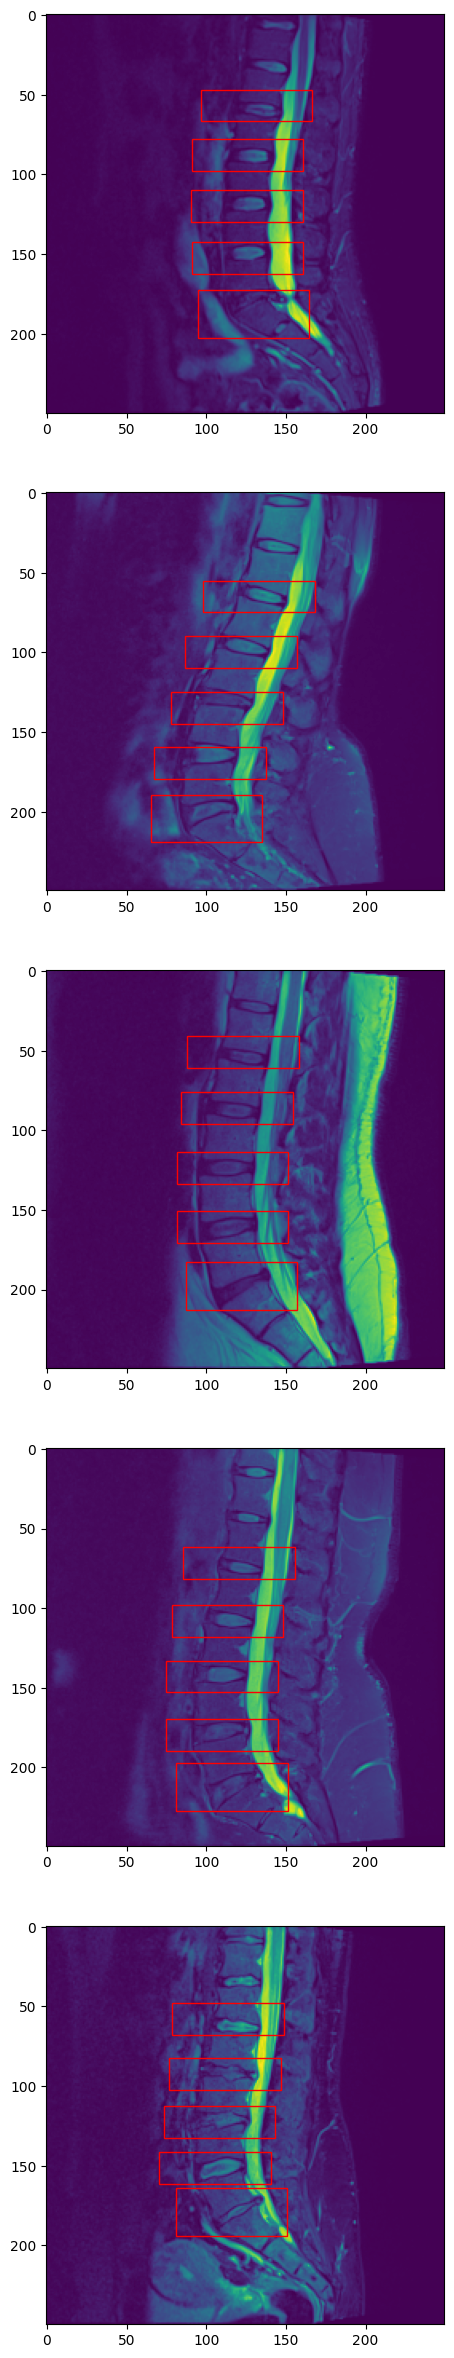

In [13]:
# Initialize dataset and data loader without collate_fn
tmp_ds = BBoxDataset(df, transforms=get_transform())
tmp_dl = torch.utils.data.DataLoader(
    tmp_ds,
    batch_size=1,
    shuffle=True
)

# Set up figure and axis for displaying images
fig, ax = plt.subplots(nrows=5, ncols=1, figsize=(30, 30))

# Iterate through the data loader and display images with bounding boxes
for i, (img, target) in enumerate(tmp_dl):
    if i == 5: break
    img = img[0]  # Since batch_size=1, img[0] is the image for this batch
    img_array = img.squeeze().numpy()

    # Show the image
    ax[i].imshow(img_array)
    
    # Draw bounding boxes
    for box in target['boxes']:
        # Check if box is a 2D array (contains multiple boxes)
        if isinstance(box, torch.Tensor):
            box = box.numpy()  # Convert tensor to numpy array if it's a tensor
        
        # If box is 2D (multiple boxes), iterate over rows
        if box.ndim == 2:
            for b in box:
                x0, y0, x1, y1 = b
                w, h = x1 - x0, y1 - y0
                ax[i].add_patch(patches.Rectangle((x0, y0), w, h, linewidth=1, edgecolor='r', facecolor='none'))
        # If it's a single box, handle it as before
        elif len(box) == 4:
            x0, y0, x1, y1 = box
            w, h = x1 - x0, y1 - y0
            ax[i].add_patch(patches.Rectangle((x0, y0), w, h, linewidth=1, edgecolor='r', facecolor='none'))
        else:
            print(f"Unexpected box format: {box}")

# Clean up after display
del tmp_ds, tmp_dl


In [14]:
import os
import torch
import torchvision
from glob import glob

def get_faster_rcnn_model(load="latest"):
    # Load a model pre-trained on COCO if not already cached
    model = torchvision.models.detection.fasterrcnn_resnet50_fpn_v2(weights="DEFAULT")

    # Number of classes (5 discs + background)
    num_classes = 6

    # Get the number of input features for the classifier
    in_features = model.roi_heads.box_predictor.cls_score.in_features

    # Replace the pre-trained head with a new one that has `num_classes`
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)

    if load:
        # Check if load is set to "latest" or a specific path
        if load == "latest":
            # If 'latest' is selected, we'll check the pre-defined file path
            model_file_path = "/kaggle/input/fasterrcnn_resnet50_fpn_v2_colab/pytorch/default/1/model_dict.pt"
            if os.path.isfile(model_file_path):
                print(f"Loading model from {model_file_path}")
                model.load_state_dict(torch.load(model_file_path))
            else:
                print("Model file not found at the provided path. Using pre-trained weights...")
        elif os.path.isfile(load):
            # If a specific file path is provided, load it
            print(f"Loading model from {load}")
            model.load_state_dict(torch.load(load))
        else:
            print("Model not found. Using pre-trained weights...")

    return model


In [15]:
model = get_faster_rcnn_model(load="latest")

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth
100%|██████████| 167M/167M [00:01<00:00, 97.6MB/s]


Loading model from /kaggle/input/fasterrcnn_resnet50_fpn_v2_colab/pytorch/default/1/model_dict.pt


In [16]:
import torch
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.models.detection import FasterRCNN

# def collate_fn(batch):
#     """
#     Custom collate function to handle batch composition for the detection task.
#     This ensures that the batch of images and corresponding targets are correctly
#     stacked for model input.
#     """
#     images = []
#     targets = []
    
#     # Iterate through the batch and collect images and targets
#     for item in batch:
#         images.append(item[0])  # image is the first element of the tuple
#         targets.append(item[1])  # target is the second element of the tuple
    
#     # Stack the images into a single tensor
#     images = torch.stack(images, dim=0)
    
#     return images, targets


# Create dataset and dataloader
dataset = BBoxDataset(df, transforms=get_transform())
data_loader = DataLoader(
    dataset,
    batch_size=2,
    shuffle=True,
    collate_fn=utils.collate_fn  # Use the custom collate_fn defined above
)

# Get first input from dataloader
images, targets = next(iter(data_loader))

# Convert images to a list (required for the model)
images = list(image for image in images)

# Prepare targets (each target is a dictionary with 'boxes', 'labels', etc.)
targets = [{k: v for k, v in t.items()} for t in targets]


In [17]:
# Inference
model.eval()
with torch.inference_mode():
    predictions = model(images)

In [18]:
# Inspect the keys of the predictions
prediction = predictions[0]  # Get the first prediction

# Print the keys of the prediction
print("Prediction Keys:", prediction.keys())

# Get the bounding boxes and their shape
boxes = prediction['boxes']
print(f"Shape of Boxes: {boxes.shape}")  # [100 boxes, 4 dims (x0, y0, x1, y1)]

# Access the first bounding box and convert it to a list
first_box = boxes[0].tolist()
print(f"First Box (x0, y0, x1, y1): {first_box}")

# Access the label of the first bounding box
first_label = prediction['labels'][0]
print(f"Label of First Box: {first_label}")

# Access the score of the first bounding box
first_score = prediction['scores'][0]
print(f"Score of First Box: {first_score}")


Prediction Keys: dict_keys(['boxes', 'labels', 'scores'])
Shape of Boxes: torch.Size([6, 4])
First Box (x0, y0, x1, y1): [70.67305755615234, 115.96612548828125, 140.0651397705078, 135.978271484375]
Label of First Box: 3
Score of First Box: 0.9985128045082092


In [19]:
import torch
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
import os
from datetime import datetime

# Split dataset into training and testing sets
train_data, test_data = train_test_split(df, shuffle=False)

# Create datasets with defined transformations
train_dataset = BBoxDataset(train_data, transforms=get_transform())
test_dataset = BBoxDataset(test_data, transforms=get_transform())

# Define training and validation data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=10,
    shuffle=True,
    collate_fn=utils.collate_fn,  # Custom collate_fn defined earlier
    num_workers=os.cpu_count()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=1,
    shuffle=False,
    collate_fn=utils.collate_fn,  # Custom collate_fn defined earlier
    num_workers=os.cpu_count()
)

# Initialize the model with the latest weights
model = get_faster_rcnn_model(load="latest")

# Move model to the correct device (e.g., GPU or CPU)
model.to(device)

# Construct the optimizer
params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.Adam(
    params,
    lr=0.0001,
)

# Set up the learning rate scheduler
lr_scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=3,
    gamma=0.1
)

# Number of epochs for training
num_epochs = 5

# Start training the model
for epoch in range(num_epochs):
    print(f"Epoch {epoch + 1}/{num_epochs}")
    
    # Train for one epoch, print every 10 iterations
    train_one_epoch(model, optimizer, train_loader, device, epoch, print_freq=10)
    
    # Update the learning rate
    lr_scheduler.step()
    
    # Evaluate on the test dataset
    evaluate(model, test_loader, device=device)

    # Save the model at the end of each epoch
    now = datetime.now().strftime("%Y_%m_%d__%H_%M_%S")
    model_dir = f'{MODEL_DIR}/{now}'
    os.makedirs(model_dir, exist_ok=True)
    model_file = f'{model_dir}/model_dict.pt'
    
    # Save the model state
    torch.save(model.state_dict(), model_file)
    print(f"Model saved to {model_file}")


Loading model from /kaggle/input/fasterrcnn_resnet50_fpn_v2_colab/pytorch/default/1/model_dict.pt
Epoch 1/5


/kaggle/working/engine.py:30: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=scaler is not None):


Epoch: [0]  [  0/188]  eta: 0:13:11  lr: 0.000001  loss: 0.0622 (0.0622)  loss_classifier: 0.0184 (0.0184)  loss_box_reg: 0.0431 (0.0431)  loss_objectness: 0.0000 (0.0000)  loss_rpn_box_reg: 0.0007 (0.0007)  time: 4.2123  data: 0.7544  max mem: 12835
Epoch: [0]  [ 10/188]  eta: 0:04:57  lr: 0.000006  loss: 0.0526 (0.0547)  loss_classifier: 0.0149 (0.0170)  loss_box_reg: 0.0375 (0.0368)  loss_objectness: 0.0000 (0.0003)  loss_rpn_box_reg: 0.0006 (0.0006)  time: 1.6718  data: 0.0960  max mem: 13174
Epoch: [0]  [ 20/188]  eta: 0:04:20  lr: 0.000011  loss: 0.0526 (0.0544)  loss_classifier: 0.0168 (0.0175)  loss_box_reg: 0.0357 (0.0360)  loss_objectness: 0.0000 (0.0002)  loss_rpn_box_reg: 0.0006 (0.0006)  time: 1.4168  data: 0.0298  max mem: 13174
Epoch: [0]  [ 30/188]  eta: 0:03:58  lr: 0.000017  loss: 0.0511 (0.0527)  loss_classifier: 0.0168 (0.0171)  loss_box_reg: 0.0331 (0.0349)  loss_objectness: 0.0001 (0.0002)  loss_rpn_box_reg: 0.0006 (0.0006)  time: 1.4171  data: 0.0313  max mem: 13

In [20]:
model = get_faster_rcnn_model(load="latest")
model.to(device)

print(model)

Loading model from /kaggle/input/fasterrcnn_resnet50_fpn_v2_colab/pytorch/default/1/model_dict.pt
FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(800,), max_size=1333, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      

In [21]:
LABELS_DICT = {
    1: "L1_L2",
    2: "L2_L3",
    3: "L3_L4",
    4: "L4_L5",
    5: "L5_S1"
}

def get_best_boxes(pred):
    best_boxes = {}

    for box, label, score in zip(pred['boxes'], pred['labels'], pred['scores']):
        if label.item() not in best_boxes or score > best_boxes[label.item()]['score']:
            best_boxes[label.item()] = {'box': box.tolist(), 'score': score.item()}

    result = {
        'boxes': [entry['box'] for entry in best_boxes.values()],
        'labels': list(best_boxes.keys()),
        'scores': [entry['score'] for entry in best_boxes.values()]
    }

    return result

def plot_prediction(x, pred):
    x = x[0, :]
    fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(12,8))
    ax.imshow(x, cmap="bone")
    pred = get_best_boxes(pred)
    for i in range(len(pred['boxes'])):
        x0, y0, x1, y1 = pred['boxes'][i]
        label = pred['labels'][i]
        score = pred['scores'][i]
        h = y1 - y0
        w = x1 - x0
        ax.add_patch(patches.Rectangle((x0, y0), w, h, linewidth=1, edgecolor='r', facecolor='none'))
        ax.text(x0+w+10, y0+h/2, f"{LABELS_DICT[label]} ({'{:.2f}'.format(score)})", color='r',fontsize=14)

In [22]:
model = get_faster_rcnn_model(load=PRETRAINED_MODEL_FILE)

Loading model from /kaggle/input/fasterrcnn_resnet50_fpn_v2_colab/pytorch/default/1/model_dict.pt


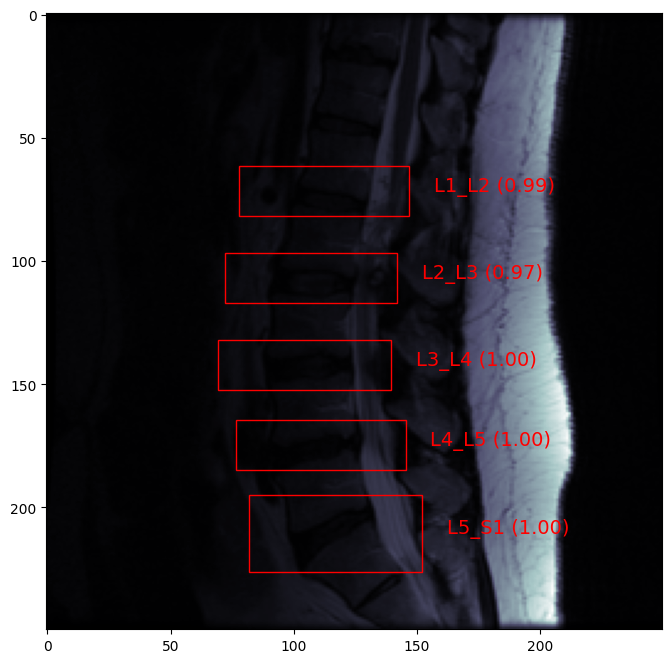

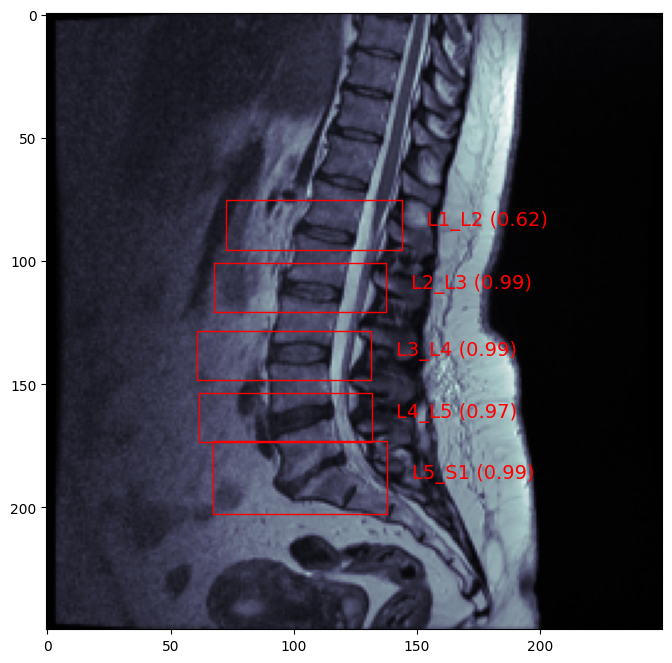

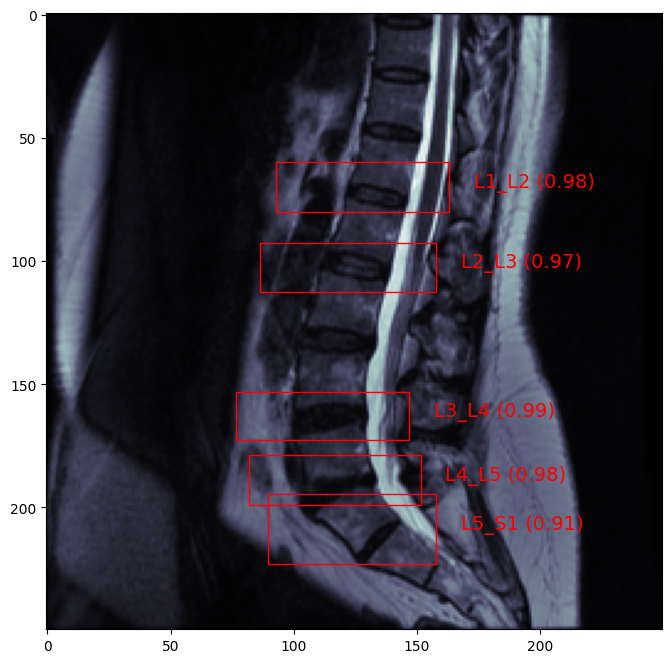

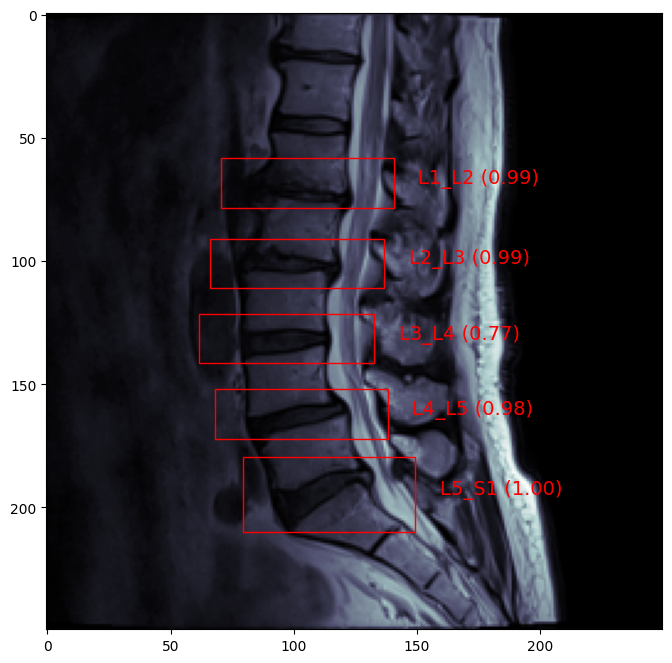

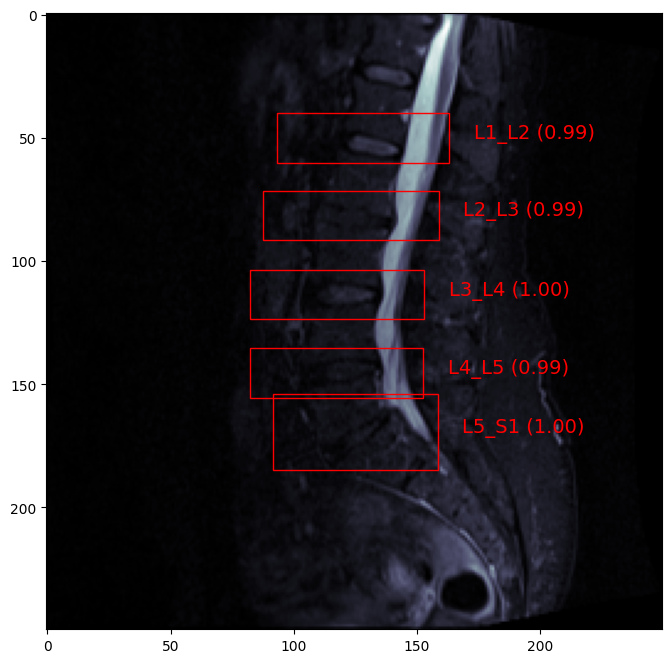

In [23]:
train_data, test_data = train_test_split(df, shuffle=False)
dataset_test = BBoxDataset(test_data, get_transform())

data_loader_test = torch.utils.data.DataLoader(
    dataset_test,
    batch_size=5,
    shuffle=False,
    collate_fn=utils.collate_fn
)

images, targets = next(iter(data_loader_test))
images = list(image.to(device) for image in images)
targets = [{k: v.to(device) if isinstance(v, torch.Tensor) else v for k, v in t.items()} for t in targets]

model.to(device)
model.eval()
with torch.inference_mode():
    predictions = model(images)

for i in range(len(images)):
    plot_prediction(images[i].cpu(), predictions[i])

Using device: cuda
Loading model...
Loading model from /kaggle/input/fasterrcnn_resnet50_fpn_v2_colab/pytorch/default/1/model_dict.pt
Model loaded successfully!
Running prediction on: /kaggle/input/rsna-2024-lumbar-spine-degenerative-classification/test_images/44036939/2828203845/14.dcm


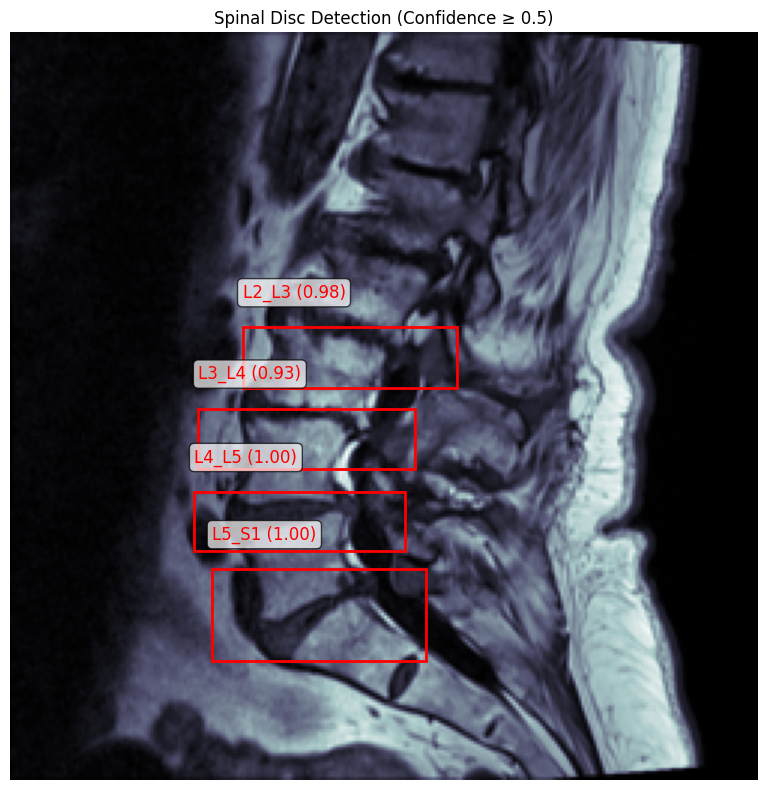


Prediction Results:
  L5_S1: 0.996
  L4_L5: 0.995
  L2_L3: 0.981
  L3_L4: 0.933


In [24]:
import torch
import torchvision
from torchvision import tv_tensors
from torchvision.tv_tensors import BoundingBoxes
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.transforms import v2 as T
import pydicom
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pandas as pd
import numpy as np

# Device configuration
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
print(f"Using device: {device}")

# Model configuration
PRETRAINED_MODEL_FILE = "/kaggle/input/fasterrcnn_resnet50_fpn_v2_colab/pytorch/default/1/model_dict.pt"

# Label mappings
DISC_LABELS = {
    "L1_L2": 1,
    "L2_L3": 2, 
    "L3_L4": 3,
    "L4_L5": 4,
    "L5_S1": 5
}

LABELS_DICT = {
    1: "L1_L2",
    2: "L2_L3",
    3: "L3_L4", 
    4: "L4_L5",
    5: "L5_S1"
}

def get_faster_rcnn_model(pretrained_path):
    """Load the Faster R-CNN model with pretrained weights"""
    model = torchvision.models.detection.fasterrcnn_resnet50_fpn_v2(weights="DEFAULT")
    
    # Number of classes (5 discs + background)
    num_classes = 6
    
    # Get the number of input features for the classifier
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    
    # Replace the pre-trained head with a new one
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
    
    # Load pretrained weights
    if pretrained_path:
        print(f"Loading model from {pretrained_path}")
        model.load_state_dict(torch.load(pretrained_path, map_location=device))
    else:
        print("Using default weights")
    
    return model

def load_image_from_path(path):
    """Load DICOM image and convert to tensor"""
    img = pydicom.dcmread(path).pixel_array
    img = (img - img.min()) / (img.max() - img.min() + 1e-6) * 255  # Normalize to 0-255
    img = tv_tensors.Image(img)  # [CHANNEL, HEIGHT, WIDTH]
    return img.double()

def get_transform():
    """Define image transformations"""
    transforms = [
        T.Resize((250, 250), antialias=True),
        T.ToDtype(torch.float, scale=True),
        T.ToPureTensor()
    ]
    return T.Compose(transforms)

def get_best_boxes(pred, confidence_threshold=0.5):
    """Filter predictions to get the best box for each class with confidence threshold"""
    best_boxes = {}
    
    for box, label, score in zip(pred['boxes'], pred['labels'], pred['scores']):
        if score < confidence_threshold:
            continue
            
        label_item = label.item()
        if label_item not in best_boxes or score > best_boxes[label_item]['score']:
            best_boxes[label_item] = {
                'box': box.tolist(), 
                'score': score.item()
            }
    
    result = {
        'boxes': [entry['box'] for entry in best_boxes.values()],
        'labels': list(best_boxes.keys()),
        'scores': [entry['score'] for entry in best_boxes.values()]
    }
    
    return result

def plot_prediction(image_tensor, prediction, confidence_threshold=0.5):
    """Plot image with predicted bounding boxes"""
    # Convert tensor to numpy for plotting
    if isinstance(image_tensor, torch.Tensor):
        image = image_tensor.cpu().squeeze().numpy()
    else:
        image = image_tensor.squeeze()
    
    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(image, cmap="bone")
    
    # Filter predictions by confidence
    filtered_pred = get_best_boxes(prediction, confidence_threshold)
    
    # Draw bounding boxes
    for i in range(len(filtered_pred['boxes'])):
        x0, y0, x1, y1 = filtered_pred['boxes'][i]
        label = filtered_pred['labels'][i]
        score = filtered_pred['scores'][i]
        
        w = x1 - x0
        h = y1 - y0
        
        # Create rectangle patch
        rect = patches.Rectangle(
            (x0, y0), w, h, 
            linewidth=2, 
            edgecolor='red', 
            facecolor='none'
        )
        ax.add_patch(rect)
        
        # Add label text
        label_text = f"{LABELS_DICT.get(label, 'Unknown')} ({score:.2f})"
        ax.text(
            x0, y0 - 10, label_text, 
            color='red', fontsize=12, 
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.7)
        )
    
    plt.title(f"Spinal Disc Detection (Confidence ≥ {confidence_threshold})")
    plt.axis('off')
    plt.tight_layout()
    plt.show()
    
    return filtered_pred

def predict_single_image(model, image_path, confidence_threshold=0.5):
    """Run prediction on a single image"""
    # Load and transform image
    original_image = load_image_from_path(image_path)
    transforms = get_transform()
    transformed_image = transforms(original_image)
    
    # Move to device and add batch dimension
    input_image = transformed_image.unsqueeze(0).to(device)
    
    # Set model to evaluation mode
    model.eval()
    
    # Run prediction
    with torch.no_grad():
        predictions = model([input_image[0]])  # Remove batch dimension for model input
    
    # Plot results
    prediction_result = plot_prediction(transformed_image, predictions[0], confidence_threshold)
    
    return prediction_result

# Load the trained model
print("Loading model...")
model = get_faster_rcnn_model(PRETRAINED_MODEL_FILE)
model.to(device)
print("Model loaded successfully!")

# Example usage:
if __name__ == "__main__":
    # Replace with your actual image path
    image_path = "/kaggle/input/rsna-2024-lumbar-spine-degenerative-classification/test_images/44036939/2828203845/14.dcm"
    
    try:
        # Run prediction
        print(f"Running prediction on: {image_path}")
        results = predict_single_image(model, image_path, confidence_threshold=0.5)
        
        # Print results
        print("\nPrediction Results:")
        for i, (label, score) in enumerate(zip(results['labels'], results['scores'])):
            print(f"  {LABELS_DICT.get(label, 'Unknown')}: {score:.3f}")
            
    except Exception as e:
        print(f"Error processing image: {e}")